# Lensed LISA MBHB waveforms — step by step
Each step calls a script in `../scripts/` (the same scripts can be run from the shell) and shows its figure.
CPU only; kernel `lensing_gw`.

In [1]:
import os, subprocess, sys, json
from IPython.display import Image, display
ROOT = os.path.abspath('..') if os.path.basename(os.getcwd()) == 'Notebooks' else os.getcwd()
def run(script, *args):
    r = subprocess.run([sys.executable, os.path.join(ROOT, 'scripts', script), *args], capture_output=True, text=True)
    print('\n'.join(l for l in r.stdout.splitlines() if 'pkg-config' not in l)); print(r.stderr[-1500:] if r.returncode else '')
    r.check_returncode()

## 1–2. Choose a waveform and build the LISA signal
PyCBC offers many frequency-domain Phenom approximants; for aligned-spin MBHBs we compare
`IMRPhenomD` (22 mode only), `IMRPhenomHM` and `IMRPhenomXHM` (higher modes). The signal is projected onto
TDI A/E/T (finite-arm-length, orbit-dependent response) and weighted by the SciRDv1 noise.
Approximants differ by a time-origin convention, so their mismatch is maximised over a time shift (~2% = higher-mode content).

PyCBC Phenom FD approximants: ['IMRPhenomA', 'IMRPhenomB', 'IMRPhenomC', 'IMRPhenomD', 'IMRPhenomNSBH', 'IMRPhenomHM', 'IMRPhenomP', 'IMRPhenomPv2', 'IMRPhenomXAS', 'IMRPhenomXHM', 'IMRPhenomPv3', 'IMRPhenomPv3HM', 'IMRPhenomXP', 'IMRPhenomXPHM', 'IMRPhenomXO4a', 'IMRPhenomXPNR', 'IMRPhenomC_INTERP', 'IMRPhenomD_INTERP', 'IMRPhenomPv2_INTERP', 'IMRPhenomHM_INTERP', 'IMRPhenomPv3HM_INTERP', 'IMRPhenomXHM_INTERP', 'IMRPhenomXPHM_INTERP']
detector-frame m1=1.000e+06 m2=5.000e+05 dL=6791 Mpc
IMRPhenomD     SNR=   3376.5  A=2734 E=1982 T=21.5  (103338 freq points)
IMRPhenomXHM   SNR=   3402.8  A=2770 E=1976 T=23.4  (103338 freq points)
IMRPhenomHM    SNR=   3415.1  A=2772 E=1994 T=24.8  (103338 freq points)
mismatch IMRPhenomXHM vs IMRPhenomD: 1.78e-02
mismatch IMRPhenomHM vs IMRPhenomD: 1.79e-02
saved figure + json in /home/singh/mbh-subhalo-lensing/scripts/../figures



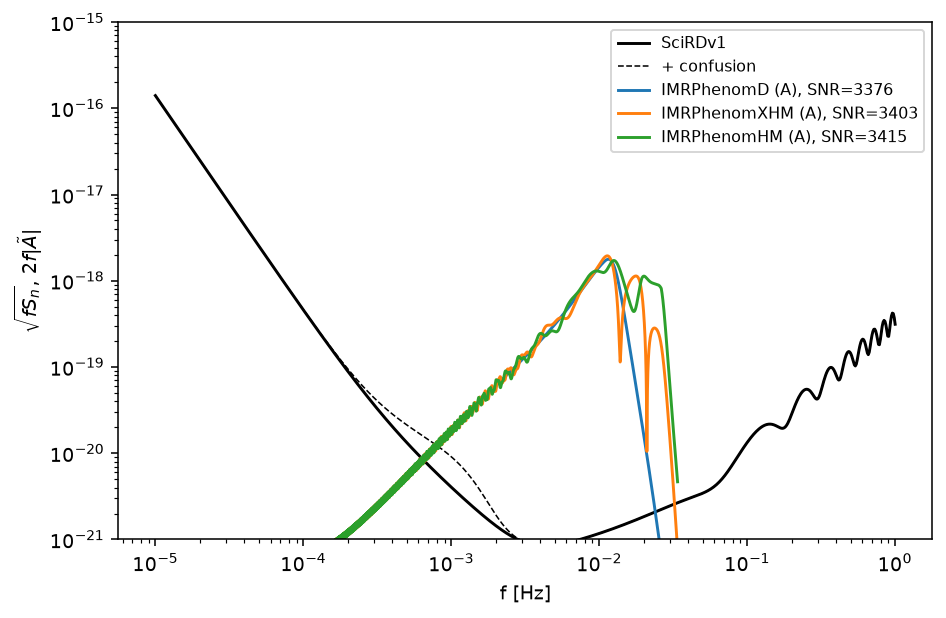

In [2]:
run('lisa_mbhb_01_waveform_snr.py')
display(Image(os.path.join(ROOT, 'figures/lisa_mbhb_01_waveform_snr.png')))

## 3. SNR
The SNR is printed above per channel (A and E dominate, T is ~1% as expected for a null channel). Sanity checks
(sky-averaged SNR, 1/d scaling, noise vs PyCBC) are in `tests/`.

In [3]:
res = json.load(open(os.path.join(ROOT, 'figures/lisa_mbhb_01_results.json')))
{k: round(v['snr'], 1) for k, v in res.items()}

{'IMRPhenomD': 3376.5, 'IMRPhenomXHM': 3402.8, 'IMRPhenomHM': 3415.1}

## 4–5. Lens the signal with GWLENS and recompute the SNR
Point-mass lens, exact wave-optics F(w, y) from `gwlens.lens.point`, `w = 8πG M_Lz f / c³`.
Small y → strong magnification and fringes; large y → F → 1.

M_Lz=1.0e+07 y=0.3: unlensed SNR=3376  lensed SNR=6710  ratio=1.987
M_Lz=1.0e+07 y=0.5: unlensed SNR=3376  lensed SNR=4889  ratio=1.448
M_Lz=1.0e+07 y=1.0: unlensed SNR=3376  lensed SNR=3881  ratio=1.149
M_Lz=1.0e+07 y=2.0: unlensed SNR=3376  lensed SNR=3476  ratio=1.029



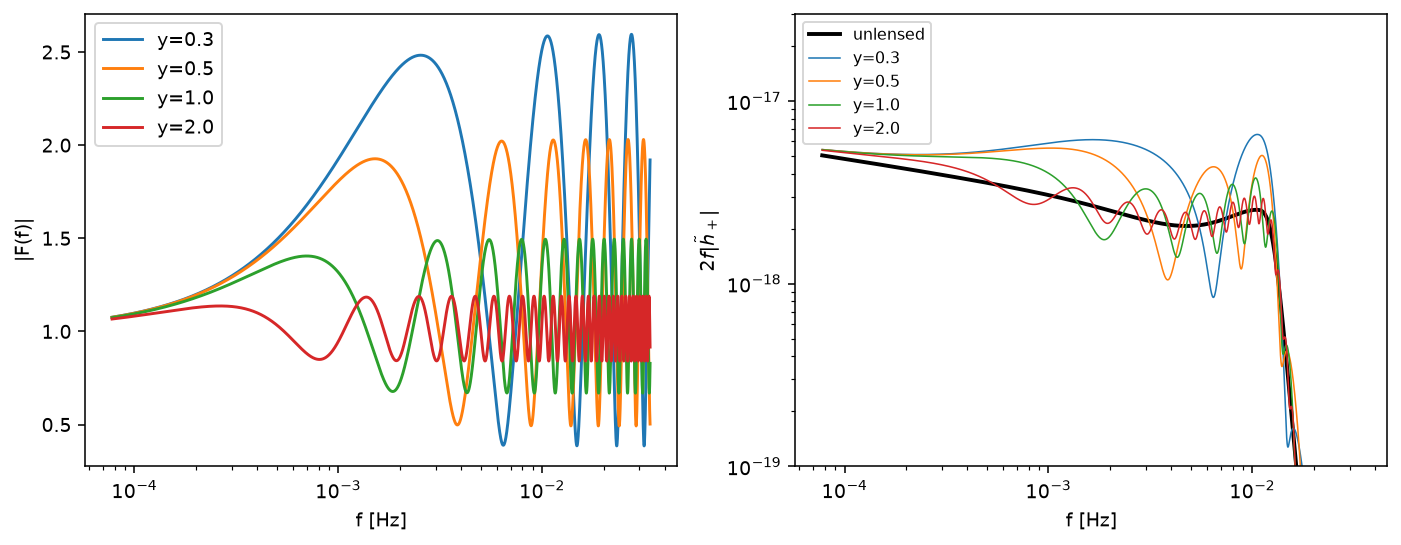

In [4]:
run('lisa_mbhb_02_lensed_snr.py', '--mass-lz', '1e7', '--y', '0.3', '0.5', '1.0', '2.0')
display(Image(os.path.join(ROOT, 'figures/lisa_mbhb_02_lensed_snr.png')))

## 6. Mismatch between lensed and unlensed signals
Mismatch = 1 − overlap, maximised over a global phase and a time shift. It falls as y grows (weaker lensing)
and is larger where lens fringes fall in LISA's band. Run with `--quick` here; drop it for the full grid.

M_Lz=1e+07 y=0.5: mismatch=1.384e-01  (SNR_lensed/unlensed=1.448)
M_Lz=1e+07 y=1.0: mismatch=6.536e-02  (SNR_lensed/unlensed=1.149)
M_Lz=1e+07 y=2.0: mismatch=1.436e-02  (SNR_lensed/unlensed=1.029)



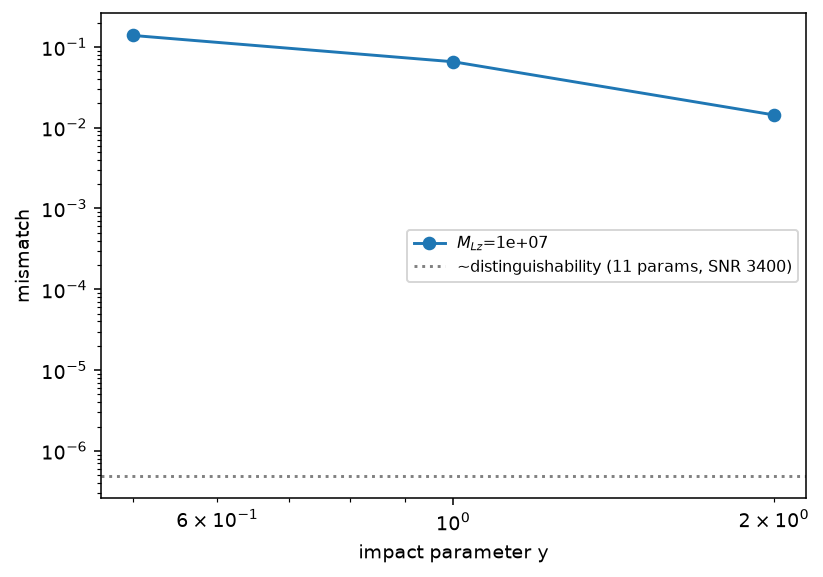

In [5]:
run('lisa_mbhb_03_mismatch.py', '--quick', '--out', os.path.join(ROOT, 'figures', 'nb_quick'))
display(Image(os.path.join(ROOT, 'figures/nb_quick/lisa_mbhb_03_mismatch.png')))

## Other lenses
Any lens with a GWLENS table: `L.LookupTableLens('table.h5', w_of_f, y)` (see `lisa_mbhb/lensing.py`); any object with
`amplification(f)` works with `LensedMBHB`.